# Spaghetti Plot (Longitudinal Trajectories)

**Family:** Scientific & clinical &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Scientific & clinical:* Specialised plots for statistics, biomedical research and model evaluation.

## Design purpose

Draws one thin line per subject for repeated measurements over time, with the group mean and its confidence band on top. Individual variation, dropout and the average trend are visible together, which a plot of means alone hides.

## When to use

- Show repeated lab values, vital signs or scores per patient over follow-up visits
- Show between-patient heterogeneity around an average trajectory
- Spot unusual individual trajectories, dropout and irregular visit timing

## Avoid when

- There are hundreds of subjects so the lines become a solid mass (sample them, use a density band, or facet by group)
- Only group averages matter and individual data cannot be shown (for privacy reasons)

## Alternatives

- Mean ± CI line chart
- Small multiples (one panel per patient for small n)
- Heatmap (patients × visits)

## Design tips

- Draw individual lines thin and gray, and the summary line thick and colored
- Highlight one illustrative patient in a contrasting color with a direct label
- Share the y-axis across panels so groups are comparable

## Example

eGFR (kidney function) measured at scheduled visits over 24 months in 40 synthetic patients per arm, with some missed visits and dropout. Placebo is compared with an active treatment.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(12)
visits = np.array([0, 3, 6, 9, 12, 18, 24])
rows = []
for arm, slope_mu in [("Placebo", -0.55), ("Treatment", -0.12)]:
    for i in range(40):
        pid = f"{arm[0]}{i:02d}"
        base = rng.normal(62, 9)
        slope = rng.normal(slope_mu, 0.25)
        if arm == "Treatment" and i == 7:
            slope = -0.9                                     # an atypical decliner to highlight
        last = rng.choice([12, 18, 24, 24, 24, 24])          # dropout
        for v in visits[visits <= last]:
            if v > 0 and rng.random() < 0.08:                # missed visit
                continue
            month = v + rng.normal(0, 0.4) if v else 0
            rows.append({"arm": arm, "patient": pid, "month": month, "visit": v,
                         "egfr": base + slope * month + rng.normal(0, 2.5)})
df = pd.DataFrame(rows)
df.head()

,arm,patient,month,visit,egfr
0,Placebo,P00,0.000000,0,63.748450
1,Placebo,P00,2.517777,3,59.644882
2,Placebo,P00,5.956899,6,62.717116
3,Placebo,P00,11.235693,12,59.065125
4,Placebo,P01,0.000000,0,56.054633


### Plot

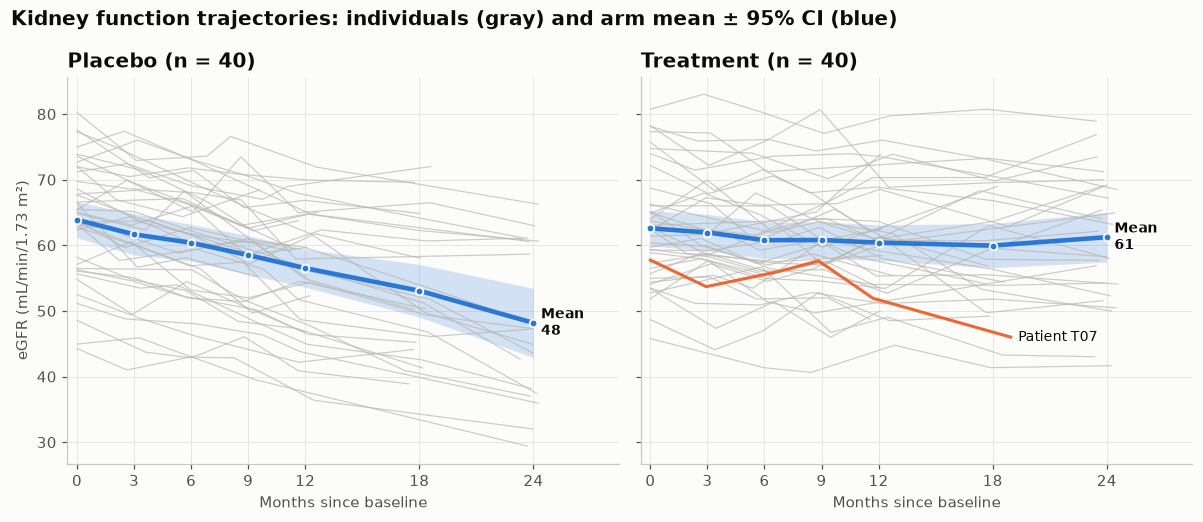

In [3]:
highlight = "T07"
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, (arm, g) in zip(axes, df.groupby("arm")):
    for pid, p in g.groupby("patient"):
        if pid != highlight:
            ax.plot(p["month"], p["egfr"], color=GRAY, linewidth=0.8, alpha=0.7)
    summary = g.groupby("visit")["egfr"].agg(["mean", "std", "count"])
    ci = 1.96 * summary["std"] / np.sqrt(summary["count"])
    ax.fill_between(summary.index, summary["mean"] - ci, summary["mean"] + ci, color=PALETTE[0], alpha=0.2, linewidth=0)
    ax.plot(summary.index, summary["mean"], color=PALETTE[0], linewidth=3, marker="o", markersize=5,
            markeredgecolor="#fcfcfb", markeredgewidth=1.2)
    ax.text(24.4, summary["mean"].iloc[-1], f"Mean\n{summary['mean'].iloc[-1]:.0f}", color="#0b0b0b",
            fontsize=9, va="center", fontweight="bold")
    if highlight in set(g["patient"]):
        p = g[g["patient"] == highlight]
        ax.plot(p["month"], p["egfr"], color=PALETTE[1], linewidth=2)
        ax.text(p["month"].iloc[-1] + 0.4, p["egfr"].iloc[-1], f"Patient {highlight}", color="#0b0b0b",
                fontsize=9, va="center")
    ax.set_title(f"{arm} (n = {g['patient'].nunique()})")
    ax.set_xticks(visits)
    ax.set_xlim(-0.5, 28.5)
    ax.set_xlabel("Months since baseline")
axes[0].set_ylabel("eGFR (mL/min/1.73 m²)")
fig.suptitle("Kidney function trajectories: individuals (gray) and arm mean ± 95% CI (blue)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

Gray lines are individual patients and the thick blue line is the arm mean with its 95% CI. Kidney function declines on placebo but stays roughly flat on treatment. Individual patients vary widely, and the orange patient declines steeply despite being on treatment.

---
Standalone script: [`spaghetti_longitudinal.py`](spaghetti_longitudinal.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)